## 1) Lab 4
**Clustering Handwritten Digits with Optdigits: K-Means, DBSCAN, PCA Diagnostics, and System-Aware Evaluation**

## 2)  Learning Objectives
By the end of this lab, you will be able to:

1. **Acquire** the Optdigits dataset from OpenML and **validate** schema, missingness, ranges, and duplicates for clustering readiness.
2. **Implement** a reproducible K-Means clustering baseline and **interpret** the effect of key hyperparameters on stability and runtime.
3. **Evaluate** clustering using internal metrics (inertia, Silhouette, Davies–Bouldin) and external metrics (ARI/NMI using labels **only for evaluation**).
4. **Compare** clustering pipelines with and without dimensionality reduction and **justify** tradeoffs (accuracy, latency, memory, robustness).
5. **Diagnose** clustering failures via PCA visualizations, confusion-style mapping, and error analysis of representative failures.
6. **Optimize** clustering choices (K selection, scaling, embedding) and **report** system implications (inference cost, monitoring, drift).
7. **Design** a minimal monitoring plan for unsupervised clustering in production (data drift, cluster stability, performance proxies).



## 3) Tasks
- Load Optdigits from OpenML and separate features vs labels (labels used only for evaluation).
- Validate schema: types, missing values, duplicates, and feature ranges.
- Build a preprocessing pipeline with `StandardScaler`.
- Fit a baseline K-Means clustering model and summarize cluster sizes.
- Select K using inertia + silhouette + Davies–Bouldin; justify choice.
- Add PCA for diagnostics; visualize clusters in 2D; interpret failure modes.
- Evaluate clustering externally using ARI and NMI; compare baseline vs improved pipeline.
- Compare against DBSCAN (density-based) and explain when it fails/succeeds.
- Write a short systems report: reproducibility plan + monitoring/drift signals.


**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.


## 4) References
### Official docs
- `sklearn.datasets.fetch_openml`: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_openml.html
- `sklearn.pipeline.Pipeline`: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- `sklearn.preprocessing.StandardScaler`: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- `sklearn.cluster.KMeans`: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- `sklearn.cluster.DBSCAN`: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
- `sklearn.decomposition.PCA`: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- `sklearn.metrics.silhouette_score`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html
- `sklearn.metrics.davies_bouldin_score`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html
- `sklearn.metrics.adjusted_rand_score`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html
- `sklearn.metrics.normalized_mutual_info_score`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.normalized_mutual_info_score.html

### References
- scikit-learn User Guide: https://scikit-learn.org/stable/modules/clustering.html
- Clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation

### Python Commands / Quick Reference
- Data: `fetch_openml`, `df.shape`, `df.isna().mean()`, `df.duplicated().sum()`, `df.describe()`
- Pipelines: `Pipeline([...])`, `.fit()`, `.transform()`, `.fit_predict()`
- Clustering: `KMeans(...)`, `DBSCAN(...)`, `labels = model.fit_predict(X)`
- Metrics: `silhouette_score`, `davies_bouldin_score`, `adjusted_rand_score`, `normalized_mutual_info_score`
- PCA: `PCA(n_components=2)`, `.fit_transform(X)`
- Plotting: `plt.scatter`, `plt.plot`, `plt.title`, `plt.show`

## 5) Workflow Overview
1. Setup & reproducibility  
2. Data acquisition (OpenML Optdigits)  
3. Data validation (schema, missingness, duplicates, ranges)  
4. Baseline pipeline (scaling)  
5. Baseline model (K-Means)  
6. Evaluation (internal metrics + K selection)  
7. Diagnostics (PCA visualization + error analysis)  
8. Improvement (PCA+KMeans) and comparison (DBSCAN)  
9. Systems discussion (cost, reproducibility, monitoring, drift)  
10. Reporting (tables/plots and short written answers)

---

## Dataset
**Primary dataset:** Optdigits (OpenML `data_id=28`) loaded with `fetch_openml(data_id=28, as_frame=True)`.
- 64 numeric features (8×8 pixel intensity features)
- Target digit label 0–9 (**use only for evaluation**)
- Size: ~5,600 rows × 64 features (exact count depends on OpenML version)

**Fallback dataset:** `sklearn.datasets.load_digits(as_frame=True)`


## Step 1 — Setup & reproducibility

### Coding questions
1) What failure modes cause K-Means to produce different results across runs?   
K-Means can produce different results because it uses random initialization of cluster centroids. Different starting centroids can lead to different final clusters. A low `n_init` value can make this problem more noticable. Differences in software versions, hardware, or random seeds can also cause small changes.

2) Why is nondeterminism a systems issue (testing, monitoring, reproducibility)?    
Nondeterministic results make it harder to reproduce an experiment and determine whether a change actually improved the model. It can also make automated testing less reliable because the same code may produce different results. For monitoring, changing cluster assignments could be caused by randomness instead of a real change in the data. Setting a fixed random state and recording the environment helps reduce this problem.

### Function/class selection and parameter exploration
- `sklearn.cluster.KMeans`: explore `n_clusters`, `n_init`, `random_state`, `init`, `max_iter`, `tol` with `help(KMeans)` or `KMeans?`.

- Explain how at least **four** of these parameters affect quality and runtime.
`n_clusters` controls the number of clusters and can greatly affect both quality and runtime. `n_init` controls how many different centroid initializations K-Means tries, so higher values can improve stability but increase runtime. `random_state` makes the random initialization reproducible but does not directly improve clustering quality. `max_iter` controls the maximum number of iterations, so increasing it can allow convergence but may increase runtime. `tol` controls the convergence tolerance, where a smaller value can require more iterations but may produce a more fully converged solution.

In [1]:
# Step 1: Setup & reproducibility

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Ready.")
print("RANDOM_STATE:", RANDOM_STATE)

Ready.
RANDOM_STATE: 42


### Execution interpretation questions
1) Which steps in this notebook can introduce randomness?   
K-Means can introduce randomness through centroid initialization. The `random_state` is used to make this process reproducible. PCA can also have some randomness depending on the solver and configuration, although the default solver for this dataset may be deterministic. The NumPy random seed also controls random operations that use NumPy.

2) If metrics differ between runs, what is your first debugging checklist?  
I would first check that the same random state is being used. Then I would check that the same dataset, preprocessing steps, K-Means parameters, and number of clusters are being used. I would also check the Python and scikit-learn versions and make sure the dataset has not changed. Finally, I would verify that the same rows and features are being passed into the model.

## Step 2 — Data acquisition: Optdigits from OpenML

### Coding questions
1) Why is it acceptable to use labels in an unsupervised lab if handled carefully?  
The labels can be used for evaluation because the clustering algorithm does not use them when creating the clusters. They allow us to compare the discovered clusters with the actual digit classes afterward. The important requirement is that the labels are not included as input features during clustering.

2) Predict what happens to ARI/NMI if you accidentally include the label as a feature.  
ARI and NMI would probably increase because the clustering algorithm would have direct access to information about the true digit class. However, this would be leakage because the label is supposed to be used only for evaluation. The resulting metrics would therefore give an unrealistic picture of clustering performance.

### Function/class selection + parameter exploration
- `sklearn.datasets.fetch_openml(data_id=28, as_frame=True)` and explore `as_frame`.

In [2]:
# Step 2: Data acquisition (OpenML Optdigits)
# If OpenML is unavailable, fall back to sklearn digits.

try:
    bunch = fetch_openml(data_id=28, as_frame=True)
    df = bunch.frame.copy()
    dataset_source = "OpenML (data_id=28)"
except Exception as e:
    print("OpenML load failed:", repr(e))
    print("Falling back to sklearn digits dataset.")
    from sklearn.datasets import load_digits
    bunch = load_digits(as_frame=True)
    df = bunch.frame.copy()
    df["class"] = bunch.target
    dataset_source = "sklearn.load_digits (fallback)"

print("Dataset source:", dataset_source)
print("df.shape:", df.shape)
df.head()

Dataset source: OpenML (data_id=28)
df.shape: (5620, 65)


,input1,input2,input3,input4,input5,input6,input7,input8,input9,input10,...,input56,input57,input58,input59,input60,input61,input62,input63,input64,class
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


### Execution interpretation questions
1) Why do we keep labels in the DataFrame at all?   
We keep the labels so they can be used later for external evaluation. Metrics such as ARI and NMI compare the clusters against the known digit labels. The labels are kept separate from the feature matrix so they are not accidentally used by K-Means or DBSCAN.

2) What provenance fields would you log?    
I would log the dataset name, OpenML data ID, dataset source, date accessed, number of rows and features, software versions, random state, preprocessing steps, model parameters, and evaluation results. I would also record whether the OpenML dataset or the fallback sklearn dataset was used.

## Step 3 — Data validation: schema, missingness, duplicates, ranges

### Coding questions
1) What clustering failure occurs if features contain NaNs?     
K-Means and DBSCAN generally cannot work directly with NaN values. The model may fail during fitting and produce an error. Missing values therefore need to be handled before clustering, such as through imputation or, as this lab does, dropping incomplete rows.

2) How can duplicate rows distort cluster sizes and evaluation?     
Duplicate rows can cause certain observations to receive more weight than they should. This can make some clusters appear larger and can influence where the centroids are located. It can also make evaluation metrics look different because repeated observations are being counted multiple times.

### Function/class selection and parameter exploration
- Use `df.isna()`, `df.duplicated()`, `df.describe()`, `select_dtypes`.
- Identify the label column and ensure it is excluded from features.

In [3]:
# Step 3: Validation

print("Missing rate (top 10 columns):")
print(df.isna().mean().sort_values(ascending=False).head(10))

dup_count = int(df.duplicated().sum())
print("Duplicate rows:", dup_count)

# Identify label column robustly
label_candidates = [c for c in df.columns if c.lower() in ["class", "target", "label", "y"]]
if len(label_candidates) == 0:
    raise ValueError("Could not identify label column. Inspect df.columns.")

label_col = "class" if "class" in df.columns else label_candidates[0]
print("Using label column:", label_col)

# Separate features vs label (labels used only for evaluation)
X_df = df.drop(columns=[label_col]).copy()
y = df[label_col].astype(str).copy()

# Ensure numeric features
X_df = X_df.apply(pd.to_numeric, errors="coerce")

# Deterministic handling of missing values for lab: drop incomplete rows
before = len(X_df)
mask_complete = ~X_df.isna().any(axis=1)
X_df = X_df.loc[mask_complete].copy()
y = y.loc[mask_complete].copy()
after = len(X_df)

print(f"Dropped {before - after} rows due to missing feature values.")
print("X_df shape:", X_df.shape)
print("Unique labels (evaluation only):", y.nunique())

# Range sanity check
X_df.describe().T[["min", "mean", "std", "max"]].head(12)

Missing rate (top 10 columns):
input1     0.0
input34    0.0
input36    0.0
input37    0.0
input38    0.0
input39    0.0
input40    0.0
input41    0.0
input42    0.0
input43    0.0
dtype: float64
Duplicate rows: 0
Using label column: class
Dropped 0 rows due to missing feature values.
X_df shape: (5620, 64)
Unique labels (evaluation only): 10


,min,mean,std,max
input1,0.0,0.000000,0.000000,0.0
input2,0.0,0.302135,0.879962,8.0
input3,0.0,5.393238,4.672719,16.0
input4,0.0,11.815480,4.255952,16.0
input5,0.0,11.578292,4.462546,16.0
input6,0.0,5.593772,5.631149,16.0
input7,0.0,1.379359,3.356633,16.0
input8,0.0,0.138256,1.046998,16.0
input9,0.0,0.003203,0.090423,5.0
input10,0.0,1.971174,3.098815,16.0


### Execution interpretation questions
1) What risk does row-dropping create in production?    
Row-dropping can remove valid observations and reduce the amount of available data. If missing values are more common for certain types of observations, dropping those rows can also create bias. In production, a missing-value strategy should be chosen based on the source and meaning of the missing data rather than automatically removing rows.

2) Where could leakage occur in unsupervised learning?      
Leakage can occur if information that would not be available when making a real prediction is used during preprocessing or clustering. For example, including the true digit label as a feature would directly leak the answer into the model. Leakage can also occur if preprocessing uses information from a future or evaluation dataset in a production setting.

## Step 4 — Baseline preprocessing: StandardScaler

### Coding questions
1) Why is scaling important for K-Means and DBSCAN?     
Both K-Means and DBSCAN use distances between observations. If one feature has a much larger numerical scale than the others, it can dominate the distance calculation. StandardScaler puts the features on a more comparable scale so that one feature does not have an unfair influence.

2) Predict how silhouette changes if one feature is 100× larger than others.    
The larger feature would dominate the distance calculations. This could make the clusters less meaningful and could lower the silhouette score. The exact change depends on the dataset, but the main issue is that the clustering would be driven mostly by that one feature.

### Function/class selection + parameter exploration
- `StandardScaler(with_mean, with_std)` and why persistence prevents training/inference skew.

In [4]:
# Step 4: Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

print("Scaled shape:", X_scaled.shape)

Scaled shape: (5620, 64)


### Think like an ML Systems engineer
List the minimum set of artifacts you must store to reproduce cluster assignments on another machine.   
I would store the dataset version or source, feature list, preprocessing settings, fitted StandardScaler, K-Means model, number of clusters, initialization settings, random state, software/package versions, and model parameters. The exact preprocessing and fitted model must be preserved because new data needs to be transformed in exactly the same way.

### Execution interpretation questions
1) What breaks if you update the scaler but not the clustering model?   
The new scaler may transform the data into a different feature space than the one used when the K-Means model was trained. The old centroids would then no longer represent the same coordinate system. This can cause incorrect cluster assignments.

2) How do you catch this in monitoring?     
I would track the scaler and model versions together and verify that the expected preprocessing version is being used. I would also monitor feature distributions, distances to centroids, and cluster assignment rates. A sudden change in these values could indicate a preprocessing mismatch or data drift.

## Step 5 — Baseline model: K-Means (K=10)

### Coding questions
1) Do you expect one cluster per digit? Why might this fail?    
There are ten digit classes, so K=10 could potentially produce roughly one cluster per digit. However, K-Means does not know the true labels and only groups observations based on distance. Different versions of the same digit can be spread across multiple clusters, while visually similar digits can be placed together.

2) What does a centroid represent in 64D pixel feature space?   
A centroid represents the average location of all the observations assigned to that cluster across the 64 pixel features. It can be thought of as an average digit pattern for that cluster. Because the features are scaled, the centroid represents an average in standardized pixel space.

### Function/class selection + parameter exploration
- `KMeans(n_clusters, n_init, random_state, init, max_iter, tol)`; explain `n_init` tradeoff.   
`n_init` determines how many different initial centroid configurations K-Means tries. A higher value gives K-Means more opportunities to find a better solution and generally makes the result more stable. The tradeoff is that increasing `n_init` requires more computation and therefore increases runtime.

In [5]:
# Step 5: Baseline K-Means

K_BASELINE = 10

kmeans_base = KMeans(
    n_clusters=K_BASELINE,
    n_init=20,
    random_state=RANDOM_STATE,
    max_iter=300,
)

labels_base = kmeans_base.fit_predict(X_scaled)

print("Baseline K-Means")
print("K:", K_BASELINE)
print("Inertia (SSE):", float(kmeans_base.inertia_))
print("Cluster sizes:")
print(pd.Series(labels_base).value_counts().sort_index())

Baseline K-Means
K: 10
Inertia (SSE): 225064.60809752357
Cluster sizes:
0     552
1     613
2     513
3    1190
4     536
5     564
6     707
7     802
8      32
9     111
Name: count, dtype: int64


### Execution interpretation questions
1) If one cluster is extremely small, give two hypotheses.      
One possibility is that the cluster represents a small group of unusual or difficult-to-classify digit images. Another possibility is that K-Means found a poor local solution because of centroid initialization or the chosen value of K.

2) What is K-Means inference-time cost per sample (big-O) in terms of K and d?      
The distance from one sample to each of the K centroids requires approximately O(Kd) time, where K is the number of clusters and d is the number of features.

## Step 6 — Evaluation: internal metrics + external evaluation (labels only for analysis)

### Coding questions
1) Why can good silhouette fail to align with digit labels?     
Silhouette measures how well-separated and compact the clusters are based on feature distances. It does not know anything about the actual digit labels. A cluster can be internally well organized while containing multiple digit types, so a good silhouette score does not necessarily mean the clusters match the digits.

2) Why might inertia be misleading for semantic quality?    
Inertia measures the squared distance between observations and their assigned centroids. It does not measure whether the clusters correspond to meaningful digit classes. A model can have low inertia while grouping different digits together.

### Function/class selection and parameter exploration
- `silhouette_score`, `davies_bouldin_score` (no labels)
- `adjusted_rand_score`, `normalized_mutual_info_score` (labels required; evaluation-only)

In [6]:
# Step 6: Metrics for baseline

sil_base = float(silhouette_score(X_scaled, labels_base))
dbi_base = float(davies_bouldin_score(X_scaled, labels_base))

ari_base = float(adjusted_rand_score(y, labels_base))
nmi_base = float(normalized_mutual_info_score(y, labels_base))

print("Baseline metrics")
print("  Internal: Silhouette =", sil_base)
print("  Internal: Davies–Bouldin (lower better) =", dbi_base)
print("  External (evaluation-only): ARI =", ari_base)
print("  External (evaluation-only): NMI =", nmi_base)

Baseline metrics
  Internal: Silhouette = 0.14094468067756916
  Internal: Davies–Bouldin (lower better) = 1.9411716565247807
  External (evaluation-only): ARI = 0.5418760896731152
  External (evaluation-only): NMI = 0.6631413979784557


### Execution interpretation questions
1) If silhouette increases but ARI decreases, what does that imply?     
It means the clusters became more compact or separated according to the feature-space metric, but they became less aligned with the actual digit labels. This shows that internal clustering quality and semantic alignment are not always the same thing.

2) Why can’t you rely on ARI/NMI in production monitoring?      
ARI and NMI require the true labels. In a real production clustering system, the correct labels may not be available immediately or may not exist at all. Therefore, production monitoring needs to rely on unlabeled signals such as feature drift, cluster proportions, and assignment stability.

3) What would you monitor without labels?   
I would monitor feature distributions, assignment stability, and distances to cluster centroids. Changes in these measurements could indicate data drift or that the clustering model is no longer representing the incoming data well.

## Step 7 — K selection: sweep K and compare curves

### Coding questions
1) Why does inertia always decrease as K increases?     
Increasing K gives K-Means more centroids to represent the data. With more clusters, each observation can usually be assigned to a closer centroid. Therefore, the total within-cluster squared distance, or inertia, decreases as K increases.

2) Will ARI necessarily increase with K? Why?   
No, increasing K does not guarantee that the clusters will match the actual digit classes better. K-Means may split one digit into several clusters or combine different digits, so ARI can increase or decrease depending on the clustering structure.

3) If you had no labels, which metric(s) would you trust and why?   
I would use silhouette and Davies-Bouldin together because both can be calculated without labels. Silhouette measures cluster separation and compactness, with higher values generally being better. Davies-Bouldin measures similarity between clusters, with lower values being better. I would also consider inertia and the shape of its curve rather than relying on only one metric.

### Function/class selection and parameter exploration
- Discuss impact of `n_init` and `random_state` on curve stability.

In [7]:
# Step 7: Sweep K

Ks = list(range(2, 21))
rows = []

for K in Ks:
    km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
    labs = km.fit_predict(X_scaled)

    rows.append({
        "K": K,
        "inertia": float(km.inertia_),
        "silhouette": float(silhouette_score(X_scaled, labs)),
        "davies_bouldin": float(davies_bouldin_score(X_scaled, labs)),
        "ARI_eval_only": float(adjusted_rand_score(y, labs)),
        "NMI_eval_only": float(normalized_mutual_info_score(y, labs)),
    })

k_results = pd.DataFrame(rows)
k_results.head()

,K,inertia,silhouette,davies_bouldin,ARI_eval_only,NMI_eval_only
0,2,320363.931112,0.108998,2.829937,0.133690,0.351910
1,3,299745.588455,0.101892,2.744425,0.230096,0.413112
2,4,285149.643864,0.088184,2.549468,0.293390,0.462107
3,5,271414.172274,0.099414,2.405181,0.367730,0.532866
4,6,259470.997144,0.102362,2.237289,0.407362,0.576390


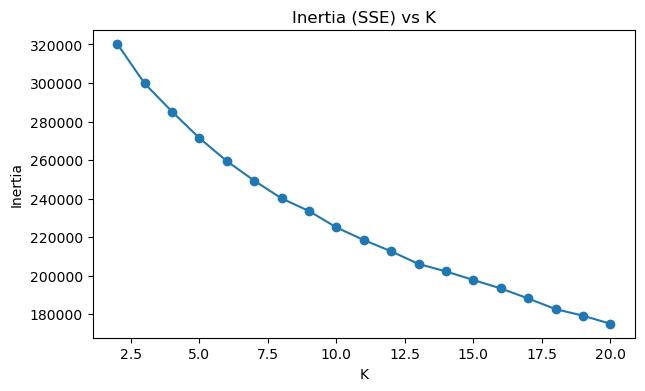

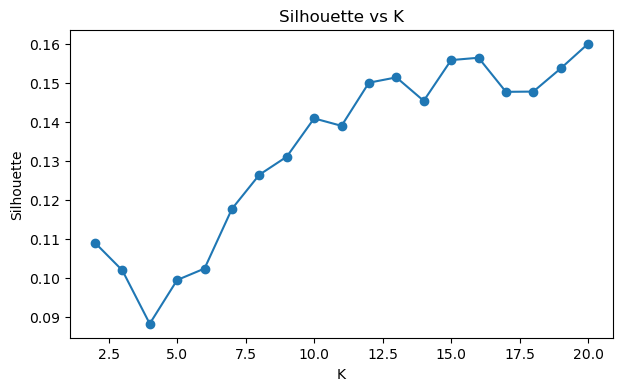

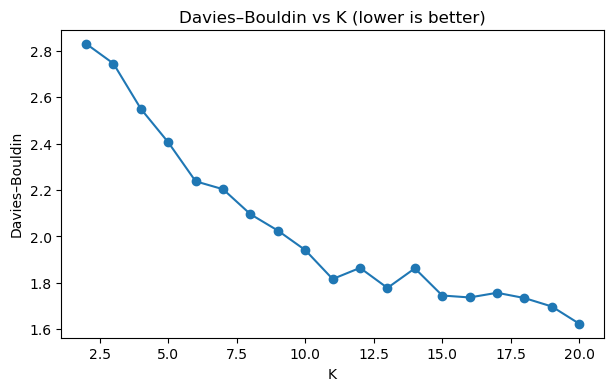

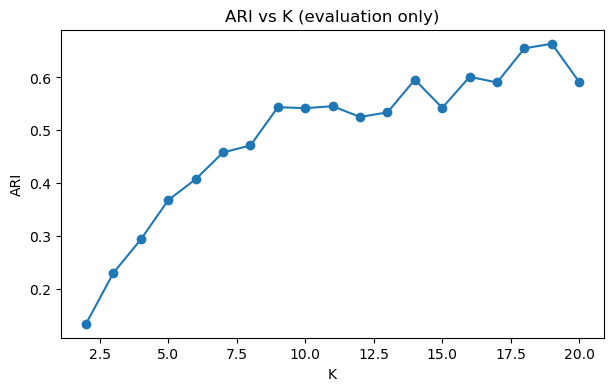

In [8]:
# Visualizations
plt.figure(figsize=(7, 4))
plt.plot(k_results["K"], k_results["inertia"], marker="o")
plt.title("Inertia (SSE) vs K")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(k_results["K"], k_results["silhouette"], marker="o")
plt.title("Silhouette vs K")
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(k_results["K"], k_results["davies_bouldin"], marker="o")
plt.title("Davies–Bouldin vs K (lower is better)")
plt.xlabel("K")
plt.ylabel("Davies–Bouldin")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(k_results["K"], k_results["ARI_eval_only"], marker="o")
plt.title("ARI vs K (evaluation only)")
plt.xlabel("K")
plt.ylabel("ARI")
plt.show()

In [9]:
# Deterministic K choice policy (no labels): maximize silhouette
# Also report best DBI for context. Then report ARI-best K (analysis only).

K_best_sil = int(k_results.loc[k_results["silhouette"].idxmax(), "K"])
K_best_dbi = int(k_results.loc[k_results["davies_bouldin"].idxmin(), "K"])
K_FINAL = K_best_sil

print("K_best_silhouette:", K_best_sil)
print("K_best_davies_bouldin:", K_best_dbi)
print("Selected K_FINAL (internal policy):", K_FINAL)

K_best_ari = int(k_results.loc[k_results["ARI_eval_only"].idxmax(), "K"])
print("K_best_ARI (evaluation only):", K_best_ari)

K_best_silhouette: 20
K_best_davies_bouldin: 20
Selected K_FINAL (internal policy): 20
K_best_ARI (evaluation only): 19


### Think like an ML Systems engineer
Without labels, how would you detect K is no longer appropriate? Propose two retrain triggers and one rollback strategy.    
One retrain trigger could be a sustained decrease in silhouette or increase in Davies-Bouldin score. Another trigger could be a large change in cluster-size proportions or distance-to-centroid distributions. For rollback, I would keep the previous validated model and switch production back to it if the new model causes a large unexpected change in assignments or monitoring metrics.

### Execution interpretation questions
1) Why might silhouette peak at small K for digits?     
Small values of K can group the data into broad, well-separated patterns. Some digit classes may share similar pixel structures, so separating every digit into its own cluster is not necessarily what maximizes geometric separation. As K increases, clusters can become more fragmented.

2) Why is the elbow method subjective?      
The inertia curve usually decreases continuously as K increases. There may not be one obvious point where the rate of improvement suddenly changes. Choosing the elbow therefore requires judgment about where additional clusters stop providing a meaningful improvement.

## Step 8 — Diagnostics: PCA visualization and cluster-to-label mapping

### Coding questions
1) Why can PCA 2D plots be misleading for cluster validation?   
PCA reduces the original 64-dimensional feature space to only two dimensions. Important information can be lost during this reduction. Two clusters that are separated in the original space may overlap in the 2D plot, so the visualization should be used for diagnosis rather than as the only measure of clustering quality.

2) What system tradeoff occurs if PCA is used in production (latency vs information loss)?      
PCA can reduce the number of features and therefore reduce the amount of data processed by K-Means. This can improve memory usage and potentially reduce inference time. However, reducing the dimensions can remove information and may decrease clustering quality or alignment with the actual classes.

### Function/class selection and parameter exploration
- `PCA(n_components=2)` for visualization; explore `n_components`, `svd_solver`.

Explained variance ratio (2 PCs): [0.11605858 0.10170154]
Sum explained variance (2 PCs): 0.21776011612330715


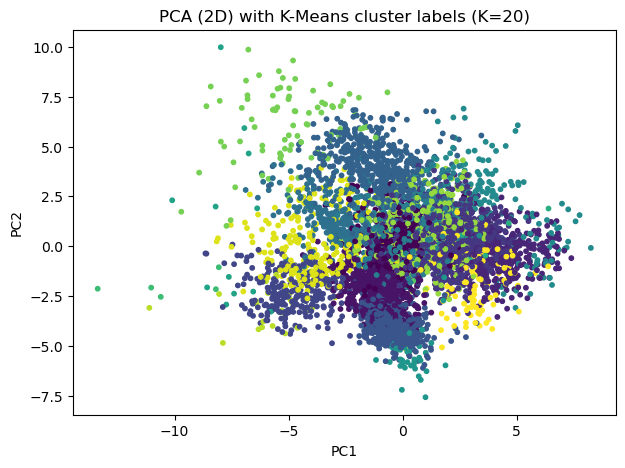

In [10]:
# Step 8: Fit final KMeans and visualize with PCA

kmeans_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=RANDOM_STATE)
labels_final = kmeans_final.fit_predict(X_scaled)

pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
Z2 = pca2.fit_transform(X_scaled)

print("Explained variance ratio (2 PCs):", pca2.explained_variance_ratio_)
print("Sum explained variance (2 PCs):", float(pca2.explained_variance_ratio_.sum()))

plt.figure(figsize=(7, 5))
plt.scatter(Z2[:, 0], Z2[:, 1], c=labels_final, s=10)
plt.title(f"PCA (2D) with K-Means cluster labels (K={K_FINAL})")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [11]:
# Cluster-to-label mapping for interpretability (labels used ONLY for analysis)

cluster_label_counts = (
    pd.DataFrame({"cluster": labels_final, "true": y.values})
    .groupby(["cluster", "true"]).size()
    .reset_index(name="count")
)

idx = cluster_label_counts.groupby("cluster")["count"].idxmax()
cluster_to_label = cluster_label_counts.loc[idx].set_index("cluster")["true"].to_dict()

mapped_pred = pd.Series(labels_final).map(cluster_to_label).astype(str)

ari_final = float(adjusted_rand_score(y, labels_final))
nmi_final = float(normalized_mutual_info_score(y, labels_final))
acc_like = float((mapped_pred.values == y.values).mean())

print("Final clustering evaluation (analysis):")
print("  ARI (eval only):", ari_final)
print("  NMI (eval only):", nmi_final)
print("  Accuracy-like via cluster->label mapping (diagnostic only):", acc_like)

cluster_label_counts.sort_values(["cluster", "count"], ascending=[True, False]).head(20)

Final clustering evaluation (analysis):
  ARI (eval only): 0.591367008074037
  NMI (eval only): 0.6967750064830751
  Accuracy-like via cluster->label mapping (diagnostic only): 0.7830960854092527


,cluster,true,count
1,0,1,322
8,0,8,60
6,0,6,12
5,0,5,10
2,0,2,9
9,0,9,5
0,0,0,2
7,0,7,2
3,0,3,1
4,0,4,1


count    5620.000000
mean        5.222864
std         1.968343
min         1.900978
50%         4.986527
90%         6.810275
95%         7.700324
99%        11.385044
max        51.293652
dtype: float64


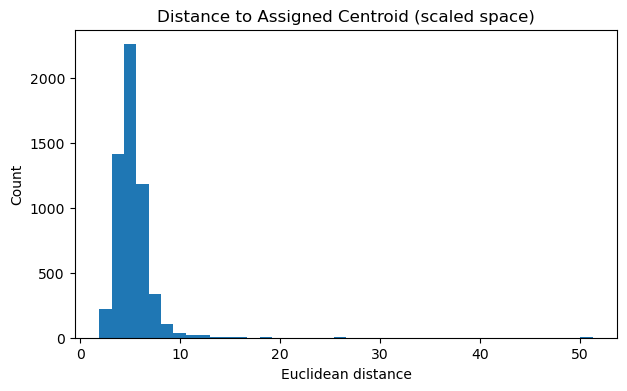

,true_label,cluster,mapped_pred,dist
0,2,17,4,51.293652
1,2,17,4,50.587247
2,8,12,8,38.279412
3,1,14,1,36.685678
4,4,17,4,30.432418
5,4,17,4,29.851311
6,4,17,4,27.098869
7,1,12,8,26.354267
8,1,12,8,26.210280
9,1,0,1,19.821558


In [12]:
# Distance-to-centroid diagnostic: large distances suggest atypical points

centroids = kmeans_final.cluster_centers_
diffs = X_scaled - centroids[labels_final]
dist_to_centroid = np.sqrt(np.sum(diffs**2, axis=1))

dist_s = pd.Series(dist_to_centroid)
print(dist_s.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

plt.figure(figsize=(7, 4))
plt.hist(dist_to_centroid, bins=40)
plt.title("Distance to Assigned Centroid (scaled space)")
plt.xlabel("Euclidean distance")
plt.ylabel("Count")
plt.show()

top_idx = np.argsort(-dist_to_centroid)[:10]
inspect = pd.DataFrame({
    "true_label": y.iloc[top_idx].values,
    "cluster": labels_final[top_idx],
    "mapped_pred": mapped_pred.iloc[top_idx].values,
    "dist": dist_to_centroid[top_idx],
})
inspect

### Execution interpretation questions
1) If PCA 2D explained variance is low, how should you interpret the scatter plot?  
The plot should be treated as a limited visualization of the data rather than a complete representation. A low explained variance means that the two components capture only a small portion of the original information. Overlap in the plot does not necessarily mean that the clusters overlap in the original 64-dimensional space.

2) Why is cluster-to-label mapping not a proper clustering objective?   
The mapping uses the true labels after clustering to give each cluster an interpretable digit name. This is useful for analysis, but the clustering algorithm itself did not use those labels. Using the mapping as the main objective would turn the evaluation into a supervised task rather than a purely unsupervised clustering problem.


3) What system risk occurs if cluster semantics shift after retraining?     
A cluster that previously represented one type of pattern may represent something different after retraining. Applications or reports that depend on a particular cluster meaning could then produce incorrect interpretations. This is why cluster stability and changes in cluster composition should be monitored after retraining.


## Step 9 — Improvement step: PCA and K-Means pipeline (runtime vs alignment tradeoff)

### Coding questions
1) Predict how reducing to 10/20/30 PCA components affects runtime and quality metrics.     
Using fewer PCA components should reduce the dimensionality of the data and generally reduce the computational and memory cost of K-Means. However, using too few components can remove information that is useful for separating the digits. Therefore, clustering quality may decrease with aggressive dimensionality reduction, while 20 or 30 components may preserve more information.

2) Why might ARI decrease even if silhouette improves in PCA space?     
PCA can make the clusters more compact and separated in the reduced feature space, which can improve silhouette. However, the information removed by PCA may include information needed to distinguish between specific digit classes. As a result, the clusters can look better geometrically while matching the true labels less closely.

### Function/class selection + parameter exploration
- `Pipeline([StandardScaler(), PCA(), KMeans()])`; interpret `n_components` as a latency/memory lever.

In [13]:
# Step 9: PCA+KMeans improvement experiments

pca_grid = [10, 20, 30]
rows = []

for n_comp in pca_grid:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_comp, random_state=RANDOM_STATE)),
        ("kmeans", KMeans(n_clusters=K_FINAL, n_init=50, random_state=RANDOM_STATE)),
    ])

    labels = pipe.fit_predict(X_df)

    X_scaled_tmp = pipe.named_steps["scaler"].transform(X_df)
    X_pca_tmp = pipe.named_steps["pca"].transform(X_scaled_tmp)

    sil = float(silhouette_score(X_pca_tmp, labels))
    dbi = float(davies_bouldin_score(X_pca_tmp, labels))
    ari = float(adjusted_rand_score(y, labels))
    nmi = float(normalized_mutual_info_score(y, labels))

    rows.append({
        "pca_components": n_comp,
        "silhouette_pca_space": sil,
        "davies_bouldin_pca_space": dbi,
        "ARI_eval_only": ari,
        "NMI_eval_only": nmi,
    })

pca_results = pd.DataFrame(rows)
pca_results

,pca_components,silhouette_pca_space,davies_bouldin_pca_space,ARI_eval_only,NMI_eval_only
0,10,0.228372,1.370480,0.488551,0.643169
1,20,0.219793,1.276174,0.585763,0.689882
2,30,0.190980,1.411501,0.653360,0.715585


### Execution interpretation questions
1) Which PCA setting would you choose if your primary constraint is latency?    
I would consider the 10-component PCA setting because it uses the fewest dimensions and should reduce the amount of data processed by K-Means. I would still verify that the resulting clustering quality is acceptable before deploying it.

2) Which would you choose if you prioritize alignment with digit labels (analysis only)?    
I would choose the PCA setting with the highest ARI or NMI in the `pca_results` table. This choice is for analysis only because the labels are not supposed to be available when selecting an unsupervised production model.

3) What must be persisted in production if you deploy PCA and KMeans?   
The fitted PCA transformation and fitted StandardScaler must be saved along with the K-Means model. I would also save the number of PCA components, K-Means parameters, feature order, random state, dataset version, and software versions. New observations must go through the same scaler and PCA transformation before being passed to K-Means.

## Step 10 — Comparison model: DBSCAN in PCA space

### Coding questions
1) Why does DBSCAN often struggle in high dimensions?   
In high-dimensional spaces, distances between observations can become less informative because many points may appear similarly far apart. This makes it harder for DBSCAN to identify meaningful neighborhoods using a single eps value. PCA can help by reducing the dimensionality before applying DBSCAN.

2) What does noise label `-1` represent operationally?      
The `-1` label represents observations that DBSCAN considers noise because they do not belong to a sufficiently dense region. Operationally, these observations could be treated as unusual cases or potential anomalies that need additional investigation.

3) Predict outcomes if `eps` is too small vs too large.     
If `eps` is too small, DBSCAN may classify many observations as noise and create many small clusters. If `eps` is too large, separate groups may be merged into large clusters and there may be very little noise. The appropriate value depends on the density and scale of the data.

### Function/class selection + parameter exploration
- `DBSCAN(eps, min_samples, metric)`; explain how `eps` and `min_samples` affect robustness and cost.

In [14]:
# Step 10: DBSCAN comparison in PCA space

pca_db = PCA(n_components=20, random_state=RANDOM_STATE)
X_20 = pca_db.fit_transform(X_scaled)

eps_values = [2.0, 2.5, 3.0]
min_samples_values = [5, 10]

rows = []
for eps in eps_values:
    for ms in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=ms)
        labs = db.fit_predict(X_20)

        n_noise = int((labs == -1).sum())
        n_clusters = len([c for c in set(labs) if c != -1])

        mask = labs != -1
        if n_clusters >= 2 and mask.sum() > n_clusters:
            sil = float(silhouette_score(X_20[mask], labs[mask]))
            dbi = float(davies_bouldin_score(X_20[mask], labs[mask]))
        else:
            sil = np.nan
            dbi = np.nan

        ari = float(adjusted_rand_score(y, labs))
        nmi = float(normalized_mutual_info_score(y, labs))

        rows.append({
            "eps": eps,
            "min_samples": ms,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "silhouette_non_noise": sil,
            "davies_bouldin_non_noise": dbi,
            "ARI_eval_only": ari,
            "NMI_eval_only": nmi,
        })

dbscan_results = pd.DataFrame(rows).sort_values(by=["n_clusters", "n_noise"], ascending=[False, True])
dbscan_results

,eps,min_samples,n_clusters,n_noise,silhouette_non_noise,davies_bouldin_non_noise,ARI_eval_only,NMI_eval_only
0,2.0,5,64,3635,0.146579,1.236643,0.082193,0.435997
2,2.5,5,26,1543,-0.014551,1.245887,0.284906,0.557346
1,2.0,10,12,4543,0.388174,1.227709,0.037868,0.302254
3,2.5,10,11,2255,0.245880,1.264659,0.267976,0.601871
4,3.0,5,5,610,-0.046516,1.171749,0.001405,0.026911
5,3.0,10,4,880,0.076250,1.195565,0.053513,0.216222


Chosen DBSCAN configuration:
eps                           3.000000
min_samples                   5.000000
n_clusters                    5.000000
n_noise                     610.000000
silhouette_non_noise         -0.046516
davies_bouldin_non_noise      1.171749
ARI_eval_only                 0.001405
NMI_eval_only                 0.026911
Name: 4, dtype: float64


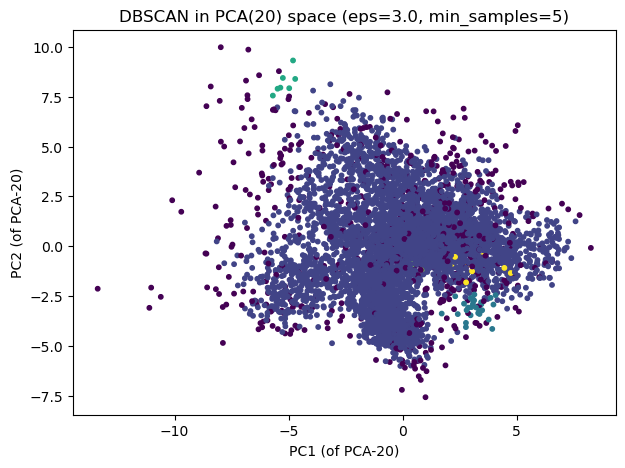

#clusters (excluding noise): 5
#noise: 610


In [15]:
# Choose a DBSCAN setting to visualize: prefer >=2 clusters and minimal noise, then best silhouette.

candidates = dbscan_results.dropna(subset=["silhouette_non_noise"]).copy()

if len(candidates) == 0:
    print("No DBSCAN configuration produced >=2 non-noise clusters suitable for silhouette.")
else:
    chosen = candidates.sort_values(by=["n_noise", "silhouette_non_noise"], ascending=[True, False]).iloc[0]
    eps_star = float(chosen["eps"])
    ms_star = int(chosen["min_samples"])

    print("Chosen DBSCAN configuration:")
    print(chosen)

    db_star = DBSCAN(eps=eps_star, min_samples=ms_star)
    labels_db = db_star.fit_predict(X_20)

    plt.figure(figsize=(7, 5))
    plt.scatter(X_20[:, 0], X_20[:, 1], c=labels_db, s=10)
    plt.title(f"DBSCAN in PCA(20) space (eps={eps_star}, min_samples={ms_star})")
    plt.xlabel("PC1 (of PCA-20)")
    plt.ylabel("PC2 (of PCA-20)")
    plt.show()

    print("#clusters (excluding noise):", len([c for c in set(labels_db) if c != -1]))
    print("#noise:", int((labels_db == -1).sum()))

### Think like an ML Systems engineer
If DBSCAN is deployed for “noise/anomaly” detection, what would you monitor weekly and why (noise rate drift, feature drift, review outcomes)?  
I would monitor the percentage of observations labeled as noise because a sudden increase could indicate data drift or a change in the system. I would also monitor feature distributions to identify changes in incoming data. If human review outcomes are available, I would compare noise detections with those outcomes to determine whether the detected anomalies remain useful.

### Execution interpretation questions
1) If DBSCAN returns mostly noise, what are two likely causes?  
One likely cause is that `eps` is too small, so very few observations are considered neighbors. Another possibility is that the data does not contain sufficiently dense groups for the selected `min_samples` value. The PCA representation and feature scaling can also affect the distances used by DBSCAN.

2) Compare inference-time cost bounding for DBSCAN vs K-Means.      
K-Means has a relatively straightforward per-sample cost because a new observation can be compared with the K centroids, approximately O(Kd). DBSCAN does not have the same simple fixed K-centroid bound because it depends on neighborhood searches and the data structure used. In practice, DBSCAN inference can be more difficult to bound and manage for large datasets.


## Step 11 — Systems reporting: minimal model card

### Coding question
1) What must be logged to reproduce this experiment exactly?    
I would log the dataset source and version, number of rows and features, label column, random state, preprocessing steps, scaler parameters, PCA settings if used, K-Means and DBSCAN parameters, software versions, and all evaluation metrics. I would also save the fitted preprocessing and clustering models.

2) Without labels, what three monitoring signals would you implement?   
I would monitor feature drift, cluster-size proportions, and assignment stability. I would also monitor distances to centroids because large changes can indicate that new observations are becoming less similar to the data used to train the model.

3) What rollback strategy would you use if cluster assignments shift sharply after retraining?      
I would keep the previous validated clustering model available as a rollback version. If the new model causes an unexpected increase in assignment changes or other monitoring problems, I would switch back to the previous model. I would then investigate the data, preprocessing, K selection, and model changes before attempting another deployment.

### Function/class selection + parameter exploration
- Use `.get_params()` for traceability; build a dictionary-based report.

In [16]:
# Step 11: Minimal model card / report artifact

model_card = {
    "dataset_source": dataset_source,
    "n_rows": int(len(X_df)),
    "n_features": int(X_df.shape[1]),
    "label_col_eval_only": label_col,
    "random_state": int(RANDOM_STATE),
    "scaler": "StandardScaler",
    "kmeans_final": {
        "K": int(K_FINAL),
        "params": kmeans_final.get_params(),
        "inertia": float(kmeans_final.inertia_),
        "internal_metrics": {
            "silhouette": float(silhouette_score(X_scaled, labels_final)),
            "davies_bouldin": float(davies_bouldin_score(X_scaled, labels_final)),
        },
        "external_eval_only": {
            "ARI": float(adjusted_rand_score(y, labels_final)),
            "NMI": float(normalized_mutual_info_score(y, labels_final)),
        },
    },
    "monitoring_plan": {
        "feature_drift": "Track distribution shift (e.g., KS/PSI) per feature or PCA component.",
        "cluster_size_drift": "Alert on large changes in cluster proportions.",
        "assignment_stability": "Use a fixed canary set; alert on large assignment churn.",
        "distance_shift": "Monitor distance-to-centroid distribution shifts.",
    },
    "notes": "Labels used only for evaluation; production monitoring relies on unlabeled drift signals.",
}

model_card

{'dataset_source': 'OpenML (data_id=28)',
 'n_rows': 5620,
 'n_features': 64,
 'label_col_eval_only': 'class',
 'random_state': 42,
 'scaler': 'StandardScaler',
 'kmeans_final': {'K': 20,
  'params': {'algorithm': 'lloyd',
   'copy_x': True,
   'init': 'k-means++',
   'max_iter': 300,
   'n_clusters': 20,
   'n_init': 50,
   'random_state': 42,
   'tol': 0.0001,
   'verbose': 0},
  'inertia': 175074.22249922674,
  'internal_metrics': {'silhouette': 0.16013165173057675,
   'davies_bouldin': 1.6239465299823217},
  'external_eval_only': {'ARI': 0.591367008074037, 'NMI': 0.6967750064830751}},
 'monitoring_plan': {'feature_drift': 'Track distribution shift (e.g., KS/PSI) per feature or PCA component.',
  'cluster_size_drift': 'Alert on large changes in cluster proportions.',
  'assignment_stability': 'Use a fixed canary set; alert on large assignment churn.',
  'distance_shift': 'Monitor distance-to-centroid distribution shifts.'},
 'notes': 'Labels used only for evaluation; production moni

### Execution interpretation questions
1) What is one limitation of this lab’s evaluation setup?   
One limitation is that the digit labels are available for ARI, NMI, and cluster-to-label analysis, even though those labels would not necessarily be available in a real unsupervised production system. The external metrics are useful for evaluating this experiment, but they cannot always be used for ongoing production monitoring.

2) What is your next improvement if this were deployed?     
My next improvement would be to create a stronger monitoring and validation process for production data. I would monitor feature drift, cluster proportions, assignment stability, and distance-to-centroid distributions. I would also periodically evaluate the model against newly labeled data when labels become available and retrain or roll back when the monitoring results show that the current clustering is no longer appropriate.

**End of Lab**